In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the five crop yield datasets

fields = pd.read_csv('/content/fields.csv')
soil = pd.read_csv('/content/soil.csv')
weather = pd.read_csv('/content/weather.csv')
practices = pd.read_csv('/content/practices.csv')
harvest = pd.read_csv('/content/harvest.csv')

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
# Display the number of rows and columns

datasets = {
    "Fields": fields,
    "Soil": soil,
    "Weather": weather,
    "Practices": practices,
    "Harvest": harvest
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows and {df.shape[1]} columns")

Fields: 300 rows and 4 columns
Soil: 900 rows and 7 columns
Weather: 900 rows and 5 columns
Practices: 900 rows and 5 columns
Harvest: 901 rows and 5 columns


In [4]:
# Display the first five records of each dataset

for name, df in datasets.items():
    print(f"\n--- {name} Dataset ---")
    display(df.head())



--- Fields Dataset ---


,field_id,region,area_ha,crop
0,F0001,South,1.12,Wheat
1,F0002,West,10.97,Soybean
2,F0003,South,23.52,Rice
3,F0004,West,1.23,maize
4,F0005,East,15.20,Maize



--- Soil Dataset ---


,field_id,season_year,ph,moisture_pct,nitrogen_kg_ha,phosphorus_kg_ha,potassium_kg_ha
0,F0001,2023,6.73,20.8,127.1,47.4,48.7
1,F0001,2024,6.30,34.6,51.3,21.5,75.2
2,F0001,2025,4.73,40.1,73.9,41.5,31.6
3,F0002,2023,7.31,40.6,104.7,46.8,68.5
4,F0002,2024,6.72,40.7,129.5,46.6,64.3



--- Weather Dataset ---


,field_id,season_year,rainfall_mm,temperature_c,humidity_pct
0,F0001,2023,226.6,22.9,63.7
1,F0001,2024,77.6,25.0,50.1
2,F0001,2025,115.3,23.0,56.3
3,F0002,2023,190.3,20.8,87.3
4,F0002,2024,67.5,25.6,60.1



--- Practices Dataset ---


,field_id,season_year,irrigation,fertilizer_kg_ha,sowing_date
0,F0001,2023,Sprinkler,168.5,2023-07-06
1,F0001,2024,Sprinkler,NaN,2024-04-01
2,F0001,2025,Flood,168.6,2025-07-15
3,F0002,2023,Drip,76.8,2023-03-18
4,F0002,2024,Drip,83.0,2024-12-13



--- Harvest Dataset ---


,field_id,season_year,yield_tonnes_ha,harvest_date,quality_grade
0,F0001,2023,5.71,2023-11-15,A
1,F0001,2024,3.87,2024-11-15,C
2,F0001,2025,5.16,2025-11-15,B
3,F0002,2023,5.16,2023-11-15,B
4,F0002,2024,4.31,2024-11-15,B


In [5]:
# Round 2 - Data Quality Inspection

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name}")
    print("="*50)

    print("\nColumn Data Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:", df.duplicated().sum())


DATASET: Fields

Column Data Types:
field_id     object
region       object
area_ha     float64
crop         object
dtype: object

Missing Values:
field_id    0
region      0
area_ha     0
crop        0
dtype: int64

Duplicate Rows: 0

DATASET: Soil

Column Data Types:
field_id             object
season_year           int64
ph                  float64
moisture_pct        float64
nitrogen_kg_ha      float64
phosphorus_kg_ha    float64
potassium_kg_ha     float64
dtype: object

Missing Values:
field_id            0
season_year         0
ph                  8
moisture_pct        0
nitrogen_kg_ha      0
phosphorus_kg_ha    0
potassium_kg_ha     0
dtype: int64

Duplicate Rows: 0

DATASET: Weather

Column Data Types:
field_id          object
season_year        int64
rainfall_mm      float64
temperature_c    float64
humidity_pct     float64
dtype: object

Missing Values:
field_id         0
season_year      0
rainfall_mm      0
temperature_c    0
humidity_pct     7
dtype: int64

Duplicate Row

In [7]:
# Step 3: Data Cleaning and Preprocessing

# 1. Standardize crop names
fields['crop'] = fields['crop'].str.strip().str.title()

# 2. Remove duplicate records from harvest
harvest = harvest.drop_duplicates()

# 3. Handle missing numerical values using median
soil['ph'] = soil['ph'].fillna(soil['ph'].median())
weather['humidity_pct'] = weather['humidity_pct'].fillna(
    weather['humidity_pct'].median()
)
practices['fertilizer_kg_ha'] = practices['fertilizer_kg_ha'].fillna(
    practices['fertilizer_kg_ha'].median()
)

# 4. Verify cleaning
for name, df in datasets.items():
    print(f"{name}: {df.isnull().sum().sum()} missing values")

print("\nCrop names after standardization:")
print(fields['crop'].unique())

print("\nHarvest shape after duplicate removal:", harvest.shape)
datasets['Harvest'] = harvest

Fields: 0 missing values
Soil: 0 missing values
Weather: 0 missing values
Practices: 0 missing values
Harvest: 0 missing values

Crop names after standardization:
['Wheat' 'Soybean' 'Rice' 'Maize' 'Cotton']

Harvest shape after duplicate removal: (900, 5)


In [8]:
# Basic statistics of crop yield
print(harvest['yield_tonnes_ha'].describe())
# Average yield in each region
data = fields[['field_id', 'region']].merge(
    harvest[['field_id', 'yield_tonnes_ha']], on='field_id'
)

print(data.groupby('region')['yield_tonnes_ha'].mean())

count    900.000000
mean       4.726244
std        1.625098
min        1.040000
25%        3.757500
50%        4.600000
75%        5.560000
max       35.000000
Name: yield_tonnes_ha, dtype: float64
region
Central    4.644568
East       4.651765
North      4.584485
South      4.958978
West       4.746453
Name: yield_tonnes_ha, dtype: float64


                 rainfall_mm  yield_tonnes_ha
rainfall_mm          1.00000          0.44393
yield_tonnes_ha      0.44393          1.00000


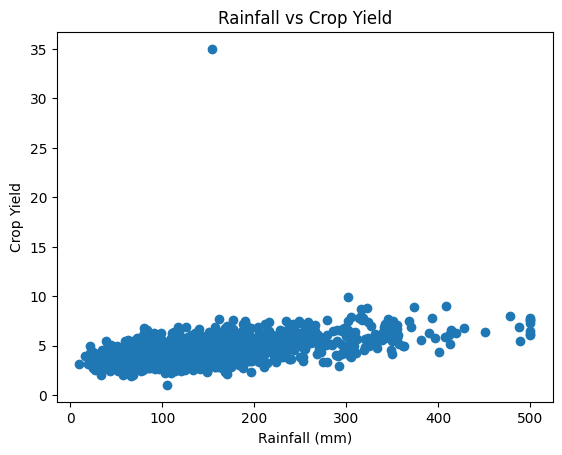

In [10]:
# Rainfall and yield relationship
data = weather.merge(
    harvest, on=['field_id', 'season_year']
)

print(data[['rainfall_mm', 'yield_tonnes_ha']].corr())
import matplotlib.pyplot as plt

plt.scatter(data['rainfall_mm'], data['yield_tonnes_ha'])
plt.xlabel('Rainfall (mm)')
plt.ylabel('Crop Yield')
plt.title('Rainfall vs Crop Yield')
plt.show()

In [11]:
# Feature Engineering
practices['sowing_date'] = pd.to_datetime(practices['sowing_date'])
practices['sowing_month'] = practices['sowing_date'].dt.month

print(practices[['sowing_date', 'sowing_month']].head())

  sowing_date  sowing_month
0  2023-07-06             7
1  2024-04-01             4
2  2025-07-15             7
3  2023-03-18             3
4  2024-12-13            12


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = fields.merge(soil, on='field_id')

In [13]:
data = fields.merge(soil, on='field_id')
data = data.merge(weather, on=['field_id', 'season_year'])
data = data.merge(practices, on=['field_id', 'season_year'])
data = data.merge(harvest, on=['field_id', 'season_year'])

data = data.drop_duplicates()
print(data.shape)

(900, 20)


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = data[['rainfall_mm', 'temperature_c', 'ph', 'nitrogen_kg_ha']]
y = data['yield_tonnes_ha']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", mean_squared_error(y_test, pred)**0.5)
print("R2:", r2_score(y_test, pred))

MAE: 0.8208199999999999
RMSE: 1.020578501907401
R2: 0.25385640454310554


In [15]:
data.to_csv('crop_yield_cleaned.csv', index=False)

from google.colab import files
files.download('crop_yield_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>